## DGT(동원) 자부두 환적 EDA 분석

In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker  # x축 눈금 형식을 바꾸기 위한 모듈

In [2]:
DGT_DGT_CSV_PATH = './data/DGT_DGT_2025.csv'

In [3]:
df = pd.read_csv(DGT_DGT_CSV_PATH)

## 데이터 정보 확인

In [4]:
df

,컨테이너번호,Class,적/공,Size/Type,화물종류,중량(kg),Seal No,BL No,양하항,적하항,...,양하모선항차,적하모선명,적하모선항차,선내위치,야드 장치 시간,트럭 진입 시간,온샤시 시간,경과료 Free Date,냉동료 Free Date,반출예정일
0,APZU3703984,TL,M,20/GE(2210),M,2230.0,NaN,WO03197300A,CNTAO,KITRW,...,PCEE-002/2025,LING YUN HE,CLYH-038/2025,NaN,2025-10-11 11:37,NaN,2025-11-12 20:51,NaN,NaN,NaN
1,AXIU6229942,TL,F,20/RF(22R1),R,20346.0,NaN,SYDA70895100,JPYOK,AUBNE,...,HHGR-001/2025,HONOR VOYAGER,HNVY-013/2025,NaN,2025-03-26 03:13,NaN,2025-04-01 16:04,NaN,NaN,NaN
2,BEAU2047832,TL,F,20/GE(2210),G,4641.0,NaN,TYOM59150000,BRSSZ,JPSMZ,...,OCNF-023/2025,NYK FUTAGO,ONFG-003/2025,NaN,2025-11-05 18:41,NaN,2025-11-12 20:41,NaN,NaN,NaN
3,BEAU4925140,TL,F,40/GE(4510),G,8763.0,NaN,SHKA041638,USLGB,CNSHK,...,KKSL-001/2025,KMTC MUNDRA,KKMU-005/2025,NaN,2025-10-02 08:32,NaN,2025-10-11 02:42,NaN,NaN,NaN
4,BEAU5175441,TL,F,40/GE(45G1),G,10435.0,NaN,CN03873000,PGMTK,TWTXG,...,SWUC-002/2025,PORT VILA CHIEF,SWPV-001/2025,NaN,2025-03-18 04:00,NaN,2025-03-24 23:59,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,TRHU7393341,TL,F,40/GE(4510),G,8880.0,NaN,TYOFJ3408700,SGSIN,JPKWS,...,OCNF-018/2025,HYUNDAI DYNASTY,HHDT-002/2025,NaN,2025-09-28 11:16,NaN,2025-10-07 15:18,NaN,NaN,NaN
152,TRHU8326190,TL,F,40/GE(45G1),G,29620.0,NaN,FREF04548700,JPSBS,SGSIN,...,OSOK-002/2025,ITX EHIME,IIEM-010/2025,NaN,2025-08-03 02:50,NaN,2025-08-07 06:25,NaN,NaN,NaN
153,TXGU5020559,TL,F,40/GE(4510),G,24500.0,NaN,PKG2651501,CNXGG,MYPKG,...,W522-008/2025,SUNNY CLOVER,KSCV-004/2025,NaN,2025-11-24 18:33,NaN,2025-12-12 16:14,NaN,NaN,NaN
154,TXGU8528991,TX,F,40/GE(45G1),G,24716.0,NaN,HDMUDALA92878900,JPHKT,USSAV,...,YWTY-001/2025,DONGJIN FIDES,DJFD-001/2025,NaN,2025-02-17 11:53,NaN,2025-02-23 04:26,NaN,NaN,NaN


In [5]:
print(df.shape)

(156, 32)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 32 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   컨테이너번호         156 non-null    str    
 1   Class          156 non-null    str    
 2   적/공            156 non-null    str    
 3   Size/Type      156 non-null    str    
 4   화물종류           156 non-null    str    
 5   중량(kg)         156 non-null    float64
 6   Seal No        0 non-null      float64
 7   BL No          156 non-null    str    
 8   양하항            156 non-null    str    
 9   적하항            156 non-null    str    
 10  야드위치           0 non-null      float64
 11  반입방식           156 non-null    str    
 12  반입시간           156 non-null    str    
 13  반출방식           156 non-null    str    
 14  반출시간           156 non-null    str    
 15  반입차량번호         0 non-null      float64
 16  반출차량번호         0 non-null      float64
 17  손상여부           1 non-null      str    
 18  IMDG           9 non-

In [7]:
df.isna().sum()

컨테이너번호             0
Class              0
적/공                0
Size/Type          0
화물종류               0
중량(kg)             0
Seal No          156
BL No              0
양하항                0
적하항                0
야드위치             156
반입방식               0
반입시간               0
반출방식               0
반출시간               0
반입차량번호           156
반출차량번호           156
손상여부             155
IMDG             147
UNNO             147
온도               151
양하모선명              0
양하모선항차             0
적하모선명              0
적하모선항차             0
선내위치             156
야드 장치 시간           0
트럭 진입 시간         156
온샤시 시간             0
경과료 Free Date    156
냉동료 Free Date    156
반출예정일            156
dtype: int64

In [8]:
pd.DataFrame({
    '자료형' : df.dtypes.astype('str'),
    '비결측수' : df.notna().sum(),
    '결측수' : df.isna().sum(),
    '결측률(%)' : df.isna().mean() * 100,
    '고유값 수' : df.nunique(dropna=True) # 결측치는 빼고 구하겠다.
})

,자료형,비결측수,결측수,결측률(%),고유값 수
컨테이너번호,str,156,0,0.000000,156
Class,str,156,0,0.000000,2
적/공,str,156,0,0.000000,2
Size/Type,str,156,0,0.000000,12
화물종류,str,156,0,0.000000,4
중량(kg),float64,156,0,0.000000,128
Seal No,float64,0,156,100.000000,0
BL No,str,156,0,0.000000,116
양하항,str,156,0,0.000000,33
적하항,str,156,0,0.000000,41


-> Seal No, 야드위치, 반입차량번호, 반출차량번호, 선내위치, 트럭 진입 시간, 경과료 Free Date, 냉동료 Free Date, 반출예정일의 총 9개 컬럼에 대한 값이 없으므로 제외하고 32-9 = 23개 컬럼만 사용하겠다.

In [9]:
df.columns

Index(['컨테이너번호', 'Class', '적/공', 'Size/Type', '화물종류', '중량(kg)', 'Seal No',
       'BL No', '양하항', '적하항', '야드위치', '반입방식', '반입시간', '반출방식', '반출시간', '반입차량번호',
       '반출차량번호', '손상여부', 'IMDG', 'UNNO', '온도', '양하모선명', '양하모선항차', '적하모선명',
       '적하모선항차', '선내위치', '야드 장치 시간', '트럭 진입 시간', '온샤시 시간', '경과료 Free Date',
       '냉동료 Free Date', '반출예정일'],
      dtype='str')

In [26]:
dgt_self_df = df[['컨테이너번호', 'Class', '적/공', 'Size/Type', '화물종류', '중량(kg)',
       'BL No', '양하항', '적하항', '반입방식', '반입시간', '반출방식', '반출시간',
       '손상여부', 'IMDG', 'UNNO', '온도', '양하모선명', '양하모선항차', '적하모선명',
       '적하모선항차', '야드 장치 시간', '온샤시 시간']].copy()

In [27]:
dgt_self_df

,컨테이너번호,Class,적/공,Size/Type,화물종류,중량(kg),BL No,양하항,적하항,반입방식,...,손상여부,IMDG,UNNO,온도,양하모선명,양하모선항차,적하모선명,적하모선항차,야드 장치 시간,온샤시 시간
0,APZU3703984,TL,M,20/GE(2210),M,2230.0,WO03197300A,CNTAO,KITRW,S,...,NaN,NaN,NaN,NaN,PACIFIC EXCELLENCE,PCEE-002/2025,LING YUN HE,CLYH-038/2025,2025-10-11 11:37,2025-11-12 20:51
1,AXIU6229942,TL,F,20/RF(22R1),R,20346.0,SYDA70895100,JPYOK,AUBNE,S,...,NaN,NaN,NaN,-20.0,HYUNDAI GRACE,HHGR-001/2025,HONOR VOYAGER,HNVY-013/2025,2025-03-26 03:13,2025-04-01 16:04
2,BEAU2047832,TL,F,20/GE(2210),G,4641.0,TYOM59150000,BRSSZ,JPSMZ,S,...,NaN,NaN,NaN,NaN,CONFIDENCE,OCNF-023/2025,NYK FUTAGO,ONFG-003/2025,2025-11-05 18:41,2025-11-12 20:41
3,BEAU4925140,TL,F,40/GE(4510),G,8763.0,SHKA041638,USLGB,CNSHK,S,...,NaN,NaN,NaN,NaN,KMTC SEOUL,KKSL-001/2025,KMTC MUNDRA,KKMU-005/2025,2025-10-02 08:32,2025-10-11 02:42
4,BEAU5175441,TL,F,40/GE(45G1),G,10435.0,CN03873000,PGMTK,TWTXG,S,...,NaN,NaN,NaN,NaN,NOUMEA CHIEF,SWUC-002/2025,PORT VILA CHIEF,SWPV-001/2025,2025-03-18 04:00,2025-03-24 23:59
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,TRHU7393341,TL,F,40/GE(4510),G,8880.0,TYOFJ3408700,SGSIN,JPKWS,S,...,NaN,NaN,NaN,NaN,CONFIDENCE,OCNF-018/2025,HYUNDAI DYNASTY,HHDT-002/2025,2025-09-28 11:16,2025-10-07 15:18
152,TRHU8326190,TL,F,40/GE(45G1),G,29620.0,FREF04548700,JPSBS,SGSIN,S,...,NaN,NaN,NaN,NaN,SEASPAN OSAKA,OSOK-002/2025,ITX EHIME,IIEM-010/2025,2025-08-03 02:50,2025-08-07 06:25
153,TXGU5020559,TL,F,40/GE(4510),G,24500.0,PKG2651501,CNXGG,MYPKG,S,...,NaN,NaN,NaN,NaN,WAN HAI 522,W522-008/2025,SUNNY CLOVER,KSCV-004/2025,2025-11-24 18:33,2025-12-12 16:14
154,TXGU8528991,TX,F,40/GE(45G1),G,24716.0,HDMUDALA92878900,JPHKT,USSAV,S,...,NaN,NaN,NaN,NaN,YM WARRANTY,YWTY-001/2025,DONGJIN FIDES,DJFD-001/2025,2025-02-17 11:53,2025-02-23 04:26


시간 자료 str -> 자료형으로 변경

In [28]:
# 시간을 나타내는 자료는 str -> datetime64 로 변경

cols = ['반입시간','반출시간','온샤시 시간','야드 장치 시간']
for col in cols:
    dgt_self_df[col] = pd.to_datetime(dgt_self_df[col])

In [29]:
print(dgt_self_df[['반입시간','반출시간','온샤시 시간','야드 장치 시간']].dtypes)

반입시간        datetime64[us]
반출시간        datetime64[us]
온샤시 시간      datetime64[us]
야드 장치 시간    datetime64[us]
dtype: object


In [30]:
# 반입시간과 반출시간 모두 2025년 1월 1일 ~ 2025년 12월 31일 안에 있는 데이터만 추출

start_date = '2025-01-01 00:00:00'
end_date = '2025-12-31 23:59:59'

filtered_df = dgt_self_df[
    (dgt_self_df['반입시간'] >= start_date) & (df['반입시간'] <= end_date) &
    (dgt_self_df['반출시간'] >= start_date) & (df['반출시간'] <= end_date)
]

filtered_df.shape

(154, 23)

## 컬럼 해석

In [15]:
# 1. 컨테이너 번호
# EX) TRHU7393341
# 앞 세자리 : 선사코드 - TRH
# 4째 자리 : 컨테이너 유형 - (U: 일반화물, J: 냉동기/발전기 등 컨테이너에 부착하는 장비, Z: 트레일러 or 섀시)
# 숫자 6자리 : 일련번호
# 마지막 1자리 숫자 : check digit

In [31]:
# 2. Class
filtered_df['Class'].unique()

# TL = (Terminal Local) : 자부두 환적
# TX = Transshipment Exportation : 환적수출 <- 의미 확인 필요

<StringArray>
['TL', 'TX']
Length: 2, dtype: str

In [32]:
# Class = 'TX' 인 행 개수
tx_count = len(filtered_df[filtered_df["Class"] == "TX"])
print(tx_count)

20


In [33]:
# Class = 'TX'인 행 전체
filtered_df[filtered_df["Class"] == "TX"][['컨테이너번호','반입시간','반출시간']]
# unpass에 화물관리번호로 조회해서 자/타부두 환적 확인 결과, TX 20건 전체 자부두 환적으로 확인 완료.
# GAOU6155084 : 자
# HMMU4058187 : 자
# HMMU6423592 : 자
# HMMU6720965 : 자
# HMMU6881717 : 자
# HMMU6909060 : 자
# HMMU7009822 : 자
# HMMU7052270 : 자
# HMMU7126198 : 자
# HMMU7142270 : 자
# KOCU4238267 : 자
# KOCU4729759 : 자
# KOCU5131864 : 자
# SKHU6358818 : 자
# SKHU6430580 : 자
# SKHU8128809 : 자
# SKHU8411824 : 자
# TXGU8528991 : 자

,컨테이너번호,반입시간,반출시간
36,GAOU6155084,2025-09-15 01:59:00,2025-09-19 01:36:00
48,HMMU4058187,2025-05-12 01:46:00,2025-05-13 12:55:00
53,HMMU6423592,2025-09-15 02:13:00,2025-09-19 01:38:00
56,HMMU6720965,2025-09-15 00:17:00,2025-09-19 01:56:00
57,HMMU6881717,2025-09-14 23:45:00,2025-09-19 02:00:00
58,HMMU6909060,2025-09-15 23:19:00,2025-09-19 02:10:00
60,HMMU7009822,2025-05-11 14:22:00,2025-05-13 12:57:00
61,HMMU7052270,2025-05-25 06:42:00,2025-05-29 08:12:00
62,HMMU7126198,2025-09-16 00:25:00,2025-09-19 02:03:00
63,HMMU7142270,2025-05-11 09:55:00,2025-05-13 12:52:00


---
TX 확인 전, TL 건으로만 분석해봄. -> 무시하셔도 됩니다.

In [34]:
# 우선 확실하게 자부두 환적인 Class = 'TL' 134 건으로만 분석 진행
tl_count = len(filtered_df[filtered_df["Class"] == "TL"])
print(tl_count)

134


In [35]:
# 공컨테이너는 환적 과정에서의 병목을 파악하기에 부적절하므로 제외하고 적컨으로만 분석 진행
filtered_2_df = filtered_df[filtered_df['적/공'] == 'F']
print(filtered_2_df)

          컨테이너번호 Class 적/공    Size/Type 화물종류   중량(kg)             BL No  \
1    AXIU6229942    TL   F  20/RF(22R1)    R  20346.0      SYDA70895100   
2    BEAU2047832    TL   F  20/GE(2210)    G   4641.0      TYOM59150000   
3    BEAU4925140    TL   F  40/GE(4510)    G   8763.0        SHKA041638   
4    BEAU5175441    TL   F  40/GE(45G1)    G  10435.0        CN03873000   
8    BMOU1263472    TL   F  20/GE(22G1)    H  26432.0        NC00145500   
..           ...   ...  ..          ...  ...      ...               ...   
151  TRHU7393341    TL   F  40/GE(4510)    G   8880.0      TYOFJ3408700   
152  TRHU8326190    TL   F  40/GE(45G1)    G  29620.0      FREF04548700   
153  TXGU5020559    TL   F  40/GE(4510)    G  24500.0        PKG2651501   
154  TXGU8528991    TX   F  40/GE(45G1)    G  24716.0  HDMUDALA92878900   
155  UETU2184932    TL   F  20/GE(22G1)    G  25280.0  SNKO011250800712   

       양하항    적하항 반입방식  ... 손상여부 IMDG    UNNO    온도           양하모선명  \
1    JPYOK  AUBNE    S  ... 

In [36]:
# 적컨 중 Class = 'TL' 인 건만 분석 진행 <- 'TX' 18 개는 추후 unipass로 자/타부두 확인
filtered_3_df = filtered_2_df[filtered_2_df['Class'] == 'TL']
print(filtered_3_df)

          컨테이너번호 Class 적/공    Size/Type 화물종류   중량(kg)             BL No  \
1    AXIU6229942    TL   F  20/RF(22R1)    R  20346.0      SYDA70895100   
2    BEAU2047832    TL   F  20/GE(2210)    G   4641.0      TYOM59150000   
3    BEAU4925140    TL   F  40/GE(4510)    G   8763.0        SHKA041638   
4    BEAU5175441    TL   F  40/GE(45G1)    G  10435.0        CN03873000   
8    BMOU1263472    TL   F  20/GE(22G1)    H  26432.0        NC00145500   
..           ...   ...  ..          ...  ...      ...               ...   
150  TRHU7307699    TL   F  40/GE(4510)    G  29860.0      FREF06428600   
151  TRHU7393341    TL   F  40/GE(4510)    G   8880.0      TYOFJ3408700   
152  TRHU8326190    TL   F  40/GE(45G1)    G  29620.0      FREF04548700   
153  TXGU5020559    TL   F  40/GE(4510)    G  24500.0        PKG2651501   
155  UETU2184932    TL   F  20/GE(22G1)    G  25280.0  SNKO011250800712   

       양하항    적하항 반입방식  ... 손상여부 IMDG    UNNO    온도           양하모선명  \
1    JPYOK  AUBNE    S  ... 

In [37]:
# 계산을 위해 반입시간, 반출시간, 온샤시 시간, 야드 장치 시간 자료 형식 날짜로 변경
filtered_3_df['반입시간'] = pd.to_datetime(filtered_3_df['반입시간'])
filtered_3_df['반출시간'] = pd.to_datetime(filtered_3_df['반출시간'])
filtered_3_df['온샤시 시간'] = pd.to_datetime(filtered_3_df['온샤시 시간'])
filtered_3_df['야드 장치 시간'] = pd.to_datetime(filtered_3_df['야드 장치 시간'])

In [23]:
# 터미널에 머무른 총 시간(반출시간-반입시간)에 대하여 '터미널 체류시간' -> '자부두환적 총시간'으로 컬럼 이름 변경
filtered_3_df = filtered_3_df.drop('터미널 체류시간', axis=1)

KeyError: "['터미널 체류시간'] not found in axis"

In [38]:
filtered_3_df['자부두환적 총시간'] = filtered_3_df['반출시간'] - filtered_3_df['반입시간']
print(filtered_3_df)

          컨테이너번호 Class 적/공    Size/Type 화물종류   중량(kg)             BL No  \
1    AXIU6229942    TL   F  20/RF(22R1)    R  20346.0      SYDA70895100   
2    BEAU2047832    TL   F  20/GE(2210)    G   4641.0      TYOM59150000   
3    BEAU4925140    TL   F  40/GE(4510)    G   8763.0        SHKA041638   
4    BEAU5175441    TL   F  40/GE(45G1)    G  10435.0        CN03873000   
8    BMOU1263472    TL   F  20/GE(22G1)    H  26432.0        NC00145500   
..           ...   ...  ..          ...  ...      ...               ...   
150  TRHU7307699    TL   F  40/GE(4510)    G  29860.0      FREF06428600   
151  TRHU7393341    TL   F  40/GE(4510)    G   8880.0      TYOFJ3408700   
152  TRHU8326190    TL   F  40/GE(45G1)    G  29620.0      FREF04548700   
153  TXGU5020559    TL   F  40/GE(4510)    G  24500.0        PKG2651501   
155  UETU2184932    TL   F  20/GE(22G1)    G  25280.0  SNKO011250800712   

       양하항    적하항 반입방식  ... IMDG    UNNO    온도           양하모선명         양하모선항차  \
1    JPYOK  AUBNE 

---
TX 제외 건 분석 끝. -> 여기까지 무시하세요.

## 컬럼 해석 계속

In [47]:
# 3. Size/Type : 컨테이너 정보
print(filtered_df['Size/Type'].value_counts())
'''
- 컨테이너 길이 : 40/20 feet
- 컨테이너 정보 : GE(General)/RF(Refrigerated)
- 괄호 안 첫 번째 숫자 = 컨테이너 길이(40/20 feet)
- 괄호 안 두 번째 숫자 : 컨테이너 높이 (2: 표준, 5: high cube)
- 괄호 안 끝 두자리 숫자 : 컨테이너 타입 코드 (G1 : 일반 드라이 컨테이너, 00/03 : 완전 밀폐형 드라이 컨테이너, 10 환기형 드라이 컨테이너, R1 : 냉동/냉장/가열 컨테이너, 30,32 : 독립형 냉동 시스템/특수 온도 조절 컨테이너)
'''

Size/Type
40/GE(45G1)    60
40/GE(4510)    39
20/GE(22G1)    17
20/GE(2210)    15
40/RF(45R1)     8
40/GE(4500)     6
20/GE(2200)     3
20/RF(22R1)     2
20/GE(2510)     1
40/RF(4530)     1
20/RF(2232)     1
40/GE(42G1)     1
Name: count, dtype: int64


In [41]:
# 4. 화물종류
print(filtered_df['화물종류'].value_counts())
'''
'M' : Multi-door 등의 특수 목적 컨테이너
'R' : Refrigerated Container 냉장/냉동 컨테이너
'G' : General Purpose Container 일반 컨테이너
'H' : Thermal Container with Removable Equipment / Insulated 단열/탈부착식 온도조절 컨테이너
'''

화물종류
G    108
M     32
H      9
R      5
Name: count, dtype: int64


"\n'M' : Multi-door 등의 특수 목적 컨테이너\n'R' : Refrigerated Container 냉장/냉동 컨테이너\n'G' : General Purpose Container 일반 컨테이너\n'H' : Thermal Container with Removable Equipment / Insulated 단열/탈부착식 온도조절 컨테이너\n"

In [42]:
# 5. 반입방식
print(filtered_df['반입방식'].value_counts())
# S : ship

반입방식
S    154
Name: count, dtype: int64


In [43]:
# 6. 반출방식
print(filtered_df['반출방식'].value_counts())
# S : ship

반출방식
S    154
Name: count, dtype: int64


In [44]:
# 7. 손상여부
print(filtered_df['손상여부'].value_counts())
# 컨테이너 손상된 1건 존재

손상여부
D    1
Name: count, dtype: int64


In [45]:
# 8. IMDG(International Maritime Dangerous Goods Code) : 국제해상위험물규칙
print(filtered_df['IMDG'].value_counts())
# IMDG 9 (기타 위험물 및 물품) 9건 존재

IMDG
9.0    9
Name: count, dtype: int64


In [46]:
# 9. UNNO(UN Number) : 위험물 고유 번호
print(filtered_df['UNNO'].value_counts())
# IMDG 9에 해당되는 위험물 고유 번호로, 환경을 오염시킬 우려가 있는 고체형 화학 제품이나 관련 폐기물/원료

UNNO
3077.0    9
Name: count, dtype: int64


### 각 공정 별 작업 시간 구하기

In [48]:
# 공컨테이너는 환적 과정에서의 병목을 파악하기에 부적절하므로 제외하고 적컨으로만 분석 진행
full_con = filtered_df[filtered_df['적/공'] == 'F']
print(full_con)

          컨테이너번호 Class 적/공    Size/Type 화물종류   중량(kg)             BL No  \
1    AXIU6229942    TL   F  20/RF(22R1)    R  20346.0      SYDA70895100   
2    BEAU2047832    TL   F  20/GE(2210)    G   4641.0      TYOM59150000   
3    BEAU4925140    TL   F  40/GE(4510)    G   8763.0        SHKA041638   
4    BEAU5175441    TL   F  40/GE(45G1)    G  10435.0        CN03873000   
8    BMOU1263472    TL   F  20/GE(22G1)    H  26432.0        NC00145500   
..           ...   ...  ..          ...  ...      ...               ...   
151  TRHU7393341    TL   F  40/GE(4510)    G   8880.0      TYOFJ3408700   
152  TRHU8326190    TL   F  40/GE(45G1)    G  29620.0      FREF04548700   
153  TXGU5020559    TL   F  40/GE(4510)    G  24500.0        PKG2651501   
154  TXGU8528991    TX   F  40/GE(45G1)    G  24716.0  HDMUDALA92878900   
155  UETU2184932    TL   F  20/GE(22G1)    G  25280.0  SNKO011250800712   

       양하항    적하항 반입방식  ... 손상여부 IMDG    UNNO    온도           양하모선명  \
1    JPYOK  AUBNE    S  ... 

In [49]:
# 계산을 위해 반입시간, 반출시간, 온샤시 시간, 야드 장치 시간 자료 형식 날짜로 변경
full_con['반입시간'] = pd.to_datetime(full_con['반입시간'])
full_con['반출시간'] = pd.to_datetime(full_con['반출시간'])
full_con['온샤시 시간'] = pd.to_datetime(full_con['온샤시 시간'])
full_con['야드 장치 시간'] = pd.to_datetime(full_con['야드 장치 시간'])

In [50]:
# 공정A. 양하~장치 (야드 장치 시간 - 반입시간)
full_con['공정A(양하~장치)'] = full_con['야드 장치 시간'] - full_con['반입시간']
print(full_con)

          컨테이너번호 Class 적/공    Size/Type 화물종류   중량(kg)             BL No  \
1    AXIU6229942    TL   F  20/RF(22R1)    R  20346.0      SYDA70895100   
2    BEAU2047832    TL   F  20/GE(2210)    G   4641.0      TYOM59150000   
3    BEAU4925140    TL   F  40/GE(4510)    G   8763.0        SHKA041638   
4    BEAU5175441    TL   F  40/GE(45G1)    G  10435.0        CN03873000   
8    BMOU1263472    TL   F  20/GE(22G1)    H  26432.0        NC00145500   
..           ...   ...  ..          ...  ...      ...               ...   
151  TRHU7393341    TL   F  40/GE(4510)    G   8880.0      TYOFJ3408700   
152  TRHU8326190    TL   F  40/GE(45G1)    G  29620.0      FREF04548700   
153  TXGU5020559    TL   F  40/GE(4510)    G  24500.0        PKG2651501   
154  TXGU8528991    TX   F  40/GE(45G1)    G  24716.0  HDMUDALA92878900   
155  UETU2184932    TL   F  20/GE(22G1)    G  25280.0  SNKO011250800712   

       양하항    적하항 반입방식  ... IMDG    UNNO    온도           양하모선명         양하모선항차  \
1    JPYOK  AUBNE 

In [86]:
# 공정A의 평균 시간
mean_process_a = full_con['공정A(양하~장치)'].mean().floor('s')
print(mean_process_a)
#소수점 값

0 days 00:13:19


In [52]:
# 공정B. 장치~온샤시 (온샤시 시간 - 야드 장치 시간)
full_con['공정B(장치~온샤시)'] = full_con['온샤시 시간'] - full_con['야드 장치 시간']
print(full_con)

          컨테이너번호 Class 적/공    Size/Type 화물종류   중량(kg)             BL No  \
1    AXIU6229942    TL   F  20/RF(22R1)    R  20346.0      SYDA70895100   
2    BEAU2047832    TL   F  20/GE(2210)    G   4641.0      TYOM59150000   
3    BEAU4925140    TL   F  40/GE(4510)    G   8763.0        SHKA041638   
4    BEAU5175441    TL   F  40/GE(45G1)    G  10435.0        CN03873000   
8    BMOU1263472    TL   F  20/GE(22G1)    H  26432.0        NC00145500   
..           ...   ...  ..          ...  ...      ...               ...   
151  TRHU7393341    TL   F  40/GE(4510)    G   8880.0      TYOFJ3408700   
152  TRHU8326190    TL   F  40/GE(45G1)    G  29620.0      FREF04548700   
153  TXGU5020559    TL   F  40/GE(4510)    G  24500.0        PKG2651501   
154  TXGU8528991    TX   F  40/GE(45G1)    G  24716.0  HDMUDALA92878900   
155  UETU2184932    TL   F  20/GE(22G1)    G  25280.0  SNKO011250800712   

       양하항    적하항 반입방식  ...    UNNO    온도           양하모선명         양하모선항차  \
1    JPYOK  AUBNE    S 

In [87]:
# 공정B 의 평균 시간
mean_process_b = full_con['공정B(장치~온샤시)'].mean().floor('s')
print(mean_process_b)

8 days 10:34:24


In [54]:
# 공정C. 온샤시~반출 (반출시간 - 온샤시 시간)
full_con['공정C(온샤시~반출)'] = full_con['반출시간'] - full_con['온샤시 시간']
print(full_con)

          컨테이너번호 Class 적/공    Size/Type 화물종류   중량(kg)             BL No  \
1    AXIU6229942    TL   F  20/RF(22R1)    R  20346.0      SYDA70895100   
2    BEAU2047832    TL   F  20/GE(2210)    G   4641.0      TYOM59150000   
3    BEAU4925140    TL   F  40/GE(4510)    G   8763.0        SHKA041638   
4    BEAU5175441    TL   F  40/GE(45G1)    G  10435.0        CN03873000   
8    BMOU1263472    TL   F  20/GE(22G1)    H  26432.0        NC00145500   
..           ...   ...  ..          ...  ...      ...               ...   
151  TRHU7393341    TL   F  40/GE(4510)    G   8880.0      TYOFJ3408700   
152  TRHU8326190    TL   F  40/GE(45G1)    G  29620.0      FREF04548700   
153  TXGU5020559    TL   F  40/GE(4510)    G  24500.0        PKG2651501   
154  TXGU8528991    TX   F  40/GE(45G1)    G  24716.0  HDMUDALA92878900   
155  UETU2184932    TL   F  20/GE(22G1)    G  25280.0  SNKO011250800712   

       양하항    적하항 반입방식  ...    온도           양하모선명         양하모선항차  \
1    JPYOK  AUBNE    S  ... -20

In [88]:
# 공정C 의 평균 시간
mean_process_c = full_con['공정C(온샤시~반출)'].mean().floor('s')
print(mean_process_c)

0 days 00:37:58


## 정리

공정A(양하 ~ 장치)의 평균 작업 시간 : 13분 19초

공정B(장치 ~ 온샤시)의 평균 작업 시간 : 8일 10시간 34분 24초   <- 분석에서 필요한지?

공정C(온샤시 ~ 반출)의 평균 작업 시간 : 37분 58초


## 각 공정 시각화

#### 1) 공정 A

In [62]:
print(full_con['공정A(양하~장치)'].describe())

count                       122
mean     0 days 00:13:19.180327
std      0 days 00:09:18.246354
min             0 days 00:05:00
25%             0 days 00:08:15
50%             0 days 00:10:00
75%             0 days 00:14:45
max             0 days 01:01:00
Name: 공정A(양하~장치), dtype: object


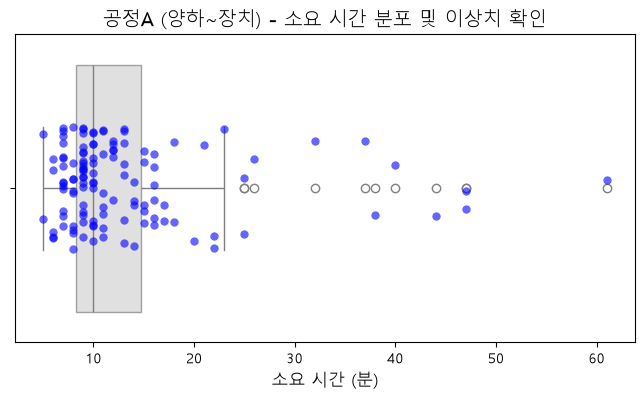

In [78]:
# 공정A
# 1. Timedelta를 직관적인 '분(minutes)' 단위 숫자로 변환한 임시 컬럼 생성
full_con['공정A_분'] = full_con['공정A(양하~장치)'].dt.total_seconds() / 60

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(8, 4))

# 2. 변환된 '공정A_분' 컬럼으로 박스플롯 그리기
sns.boxplot(
    data=full_con,
    x='공정A_분',
    color='lightgray',
    boxprops=dict(alpha=0.7)
)

# 3. 그 위에 산점도(stripplot) 겹쳐서 그리기
sns.stripplot(
    data=full_con,
    x='공정A_분',
    color='blue',
    alpha=0.6,
    jitter=0.2,
    size=6
)

plt.title('공정A (양하~장치) - 소요 시간 분포 및 이상치 확인', fontsize=14)
plt.xlabel('소요 시간 (분)', fontsize=12)  # 라벨도 '분' 단위로 명시
plt.show()

In [110]:
if '공정A_분' not in full_con.columns:
    full_con['공정A_분'] = full_con['공정A(양하~장치)'].dt.total_seconds() / 60

# 2. 주요 통계치 계산 (Q1, Q3, IQR, 평균, 중앙값)
q1 = full_con['공정A_분'].quantile(0.25)
q3 = full_con['공정A_분'].quantile(0.75)
iqr = q3 - q1

mean_val = full_con['공정A_분'].mean()
median_val = full_con['공정A_분'].median()

# 3. 박스플롯 기준 이상치 판단 기준값 계산 (일반적으로 1.5 * IQR 사용)
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# 4. 통계치 출력
print("--- [공정A 소요 시간 주요 통계] ---")
print(f"평균값 (Mean): {mean_val:.2f} 분")
print(f"중앙값 (Median, 50%): {median_val:.2f} 분")
print(f"1사분위수 (Q1): {q1:.2f} 분")
print(f"3사분위수 (Q3): {q3:.2f} 분")
print(f"IQR (Q3 - Q1): {iqr:.2f} 분")
print(f"이상치 상한 기준선 (Q3 + 1.5 * IQR): {upper_bound:.2f} 분\n")

# 5. 상한선을 초과하는 이상치 데이터 추출
outliers_a = full_con[full_con['공정A_분'] > upper_bound]

print(f"--- [이상치로 판별된 컨테이너 개수: {len(outliers_a)}개] ---")
if len(outliers_a) > 0:
    # 확인하고 싶은 주요 컬럼들과 함께 출력
    display_cols = [
        col
        for col in [
            '컨테이너번호',
            'Size/Type',
            '손상여부',
            'IMDG',
            'UNNO',
            '공정A_분',
            '반입시간',
            '야드 장치 시간',
            '온샤시 시간',
            '반출시간'
        ]
        if col in full_con.columns
    ]
    print(outliers_a[display_cols])
else:
    print("기준을 초과하는 이상치가 존재하지 않습니다.")

--- [공정A 소요 시간 주요 통계] ---
평균값 (Mean): 13.32 분
중앙값 (Median, 50%): 10.00 분
1사분위수 (Q1): 8.25 분
3사분위수 (Q3): 14.75 분
IQR (Q3 - Q1): 6.50 분
이상치 상한 기준선 (Q3 + 1.5 * IQR): 24.50 분

--- [이상치로 판별된 컨테이너 개수: 11개] ---
          컨테이너번호    Size/Type 손상여부  IMDG    UNNO  공정A_분                반입시간  \
1    AXIU6229942  20/RF(22R1)  NaN   NaN     NaN   47.0 2025-03-26 02:26:00   
26   FBIU0510229  20/GE(22G1)  NaN   9.0  3077.0   44.0 2025-08-06 21:39:00   
28   FCIU6374311  20/GE(22G1)  NaN   NaN     NaN   26.0 2025-06-05 12:23:00   
47   HMMU2236823  20/GE(2210)  NaN   NaN     NaN   40.0 2025-09-13 06:21:00   
52   HMMU6270826  40/GE(4510)  NaN   NaN     NaN   47.0 2025-10-05 22:46:00   
61   HMMU7052270  40/GE(45G1)  NaN   NaN     NaN   61.0 2025-05-25 06:42:00   
79   KOCU5222394  40/GE(4510)  NaN   NaN     NaN   38.0 2025-11-19 16:23:00   
84   ONEU0957642  40/GE(4510)  NaN   NaN     NaN   32.0 2025-11-10 00:13:00   
90   ONEU3065362  20/GE(2200)  NaN   NaN     NaN   25.0 2025-09-02 22:30:00   
107  S

-> 이상치로 계산된 11건 간의 공통점 파악이 어려움.
위험물이거나 컨테이너 사이즈가 큰 것으로 예측하였으나 사실과 다름.
데이터를 삭제하지 않고 그대로 진행함.

#### 2) 공정 B

In [92]:
print(full_con['공정B(장치~온샤시)'].describe())

count                       122
mean     8 days 10:34:24.098360
std      7 days 08:46:35.701789
min             0 days 07:58:00
25%             3 days 23:21:00
50%             6 days 08:11:00
75%            10 days 19:57:15
max            44 days 10:08:00
Name: 공정B(장치~온샤시), dtype: object


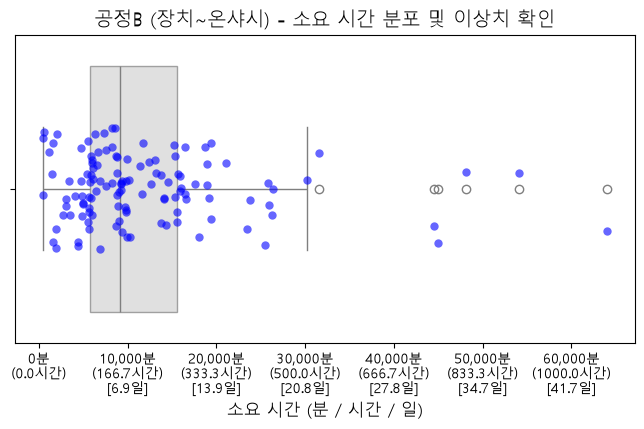

In [102]:
# 공정 B
# 1. Timedelta를 직관적인 '분(minutes)' 단위 숫자로 변환한 임시 컬럼 생성
full_con['공정B_분'] = full_con['공정B(장치~온샤시)'].dt.total_seconds() / 60

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(8, 4))

# 2. 변환된 '공정A_분' 컬럼으로 박스플롯 그리기
sns.boxplot(
    data=full_con,
    x='공정B_분',
    color='lightgray',
    boxprops=dict(alpha=0.7)
)

# 3. 그 위에 산점도(stripplot) 겹쳐서 그리기
sns.stripplot(
    data=full_con,
    x='공정B_분',
    color='blue',
    alpha=0.6,
    jitter=0.2,
    size=6
)

ax = plt.gca()  # 현재 축 가져오기

# --- 4. x축 눈금 포맷터 (총 초를 3600으로 나누어 정확한 시간 계산) ---
ax = plt.gca()

def format_func(x, pos):
    if x < 0:
        return ""

    minutes = x
    hours = x / 60         # 시간 단위 환산
    days = hours / 24      # 일(Day) 단위 환산 (1일 = 24시간)

    # 24시간(1일) 이상인 구간과 미만인 구간을 보기 좋게 분기 처리
    if hours >= 24:
        return f"{int(minutes):,}분\n({hours:.1f}시간)\n[{days:.1f}일]"
    else:
        return f"{int(minutes):,}분\n({hours:.1f}시간)"

ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_func))

plt.title('공정B (장치~온샤시) - 소요 시간 분포 및 이상치 확인', fontsize=14)
plt.xlabel('소요 시간 (분 / 시간 / 일)', fontsize=12)
plt.show()

In [111]:
if '공정B_분' not in full_con.columns:
    full_con['공정B_분'] = full_con['공정B(장치~온샤시)'].dt.total_seconds() / 60

# 2. 주요 통계치 계산 (Q1, Q3, IQR, 평균, 중앙값)
q1 = full_con['공정B_분'].quantile(0.25)
q3 = full_con['공정B_분'].quantile(0.75)
iqr = q3 - q1

mean_val = full_con['공정B_분'].mean()
median_val = full_con['공정B_분'].median()

# 3. 박스플롯 기준 이상치 판단 기준값 계산 (일반적으로 1.5 * IQR 사용)
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# 4. 통계치 출력
print("--- [공정B 소요 시간 주요 통계] ---")
print(f"평균값 (Mean): {mean_val:.2f} 분")
print(f"중앙값 (Median, 50%): {median_val:.2f} 분")
print(f"1사분위수 (Q1): {q1:.2f} 분")
print(f"3사분위수 (Q3): {q3:.2f} 분")
print(f"IQR (Q3 - Q1): {iqr:.2f} 분")
print(f"이상치 상한 기준선 (Q3 + 1.5 * IQR): {upper_bound:.2f} 분\n")

# 5. 상한선을 초과하는 이상치 데이터 추출
outliers_b = full_con[full_con['공정B_분'] > upper_bound]

print(f"--- [이상치로 판별된 컨테이너 개수: {len(outliers_b)}개] ---")
if len(outliers_b) > 0:
    # 확인하고 싶은 주요 컬럼들과 함께 출력
    display_cols = [
        col
        for col in [
            '컨테이너번호',
            'Size/Type',
            '손상여부',
            'IMDG',
            'UNNO',
            '공정B_분',
            '반입시간',
            '야드 장치 시간',
            '온샤시 시간',
            '반출시간'
        ]
        if col in full_con.columns
    ]
    print(outliers_b[display_cols])
else:
    print("기준을 초과하는 이상치가 존재하지 않습니다.")

--- [공정B 소요 시간 주요 통계] ---
평균값 (Mean): 12154.40 분
중앙값 (Median, 50%): 9131.00 분
1사분위수 (Q1): 5721.00 분
3사분위수 (Q3): 15597.25 분
IQR (Q3 - Q1): 9876.25 분
이상치 상한 기준선 (Q3 + 1.5 * IQR): 30411.62 분

--- [이상치로 판별된 컨테이너 개수: 6개] ---
          컨테이너번호    Size/Type 손상여부  IMDG  UNNO    공정B_분                반입시간  \
64   JSSU1593923  20/GE(2210)  NaN   NaN   NaN  31532.0 2025-10-09 12:22:00   
106  SEGU1977163  20/GE(22G1)  NaN   NaN   NaN  63968.0 2025-01-30 17:47:00   
130  TEMU2455560  20/GE(2210)  NaN   NaN   NaN  44990.0 2025-10-05 12:53:00   
131  TEMU5662601  20/GE(22G1)  NaN   NaN   NaN  54113.0 2025-06-11 03:16:00   
134  TEMU8533470  40/GE(4500)  NaN   NaN   NaN  44475.0 2025-11-13 07:36:00   
136  TGHU6884760  40/GE(45G1)  NaN   NaN   NaN  48097.0 2025-06-15 23:23:00   

               야드 장치 시간              온샤시 시간                반출시간  
64  2025-10-09 12:34:00 2025-10-31 10:06:00 2025-10-31 15:36:00  
106 2025-01-30 18:01:00 2025-03-16 04:09:00 2025-03-16 04:37:00  
130 2025-10-05 13:03:00 2025

-> 이상치로 계산된 6건 간의 공통점 파악이 어려움.
위험물이거나 컨테이너 사이즈가 큰 것으로 예측하였으나 사실과 다름.
데이터를 삭제하지 않고 그대로 진행함.

### 3) 공정 C

In [104]:
print(full_con['공정C(온샤시~반출)'].describe())

count                       122
mean     0 days 00:37:58.524590
std      0 days 00:38:34.315018
min             0 days 00:07:00
25%             0 days 00:18:00
50%             0 days 00:26:00
75%             0 days 00:42:00
max             0 days 05:30:00
Name: 공정C(온샤시~반출), dtype: object


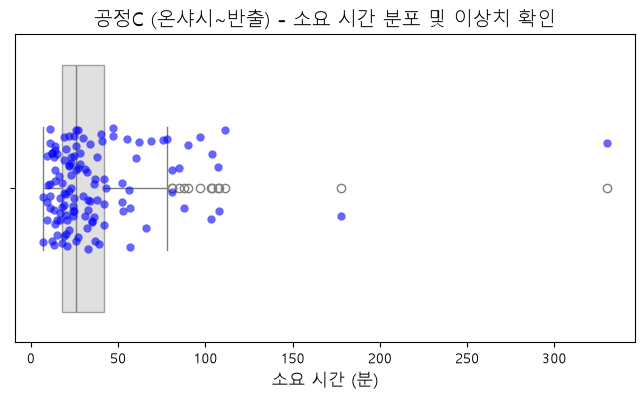

In [105]:
# 공정C
# 1. Timedelta를 직관적인 '분(minutes)' 단위 숫자로 변환한 임시 컬럼 생성
full_con['공정C_분'] = full_con['공정C(온샤시~반출)'].dt.total_seconds() / 60

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(8, 4))

# 2. 변환된 '공정A_분' 컬럼으로 박스플롯 그리기
sns.boxplot(
    data=full_con,
    x='공정C_분',
    color='lightgray',
    boxprops=dict(alpha=0.7)
)

# 3. 그 위에 산점도(stripplot) 겹쳐서 그리기
sns.stripplot(
    data=full_con,
    x='공정C_분',
    color='blue',
    alpha=0.6,
    jitter=0.2,
    size=6
)

plt.title('공정C (온샤시~반출) - 소요 시간 분포 및 이상치 확인', fontsize=14)
plt.xlabel('소요 시간 (분)', fontsize=12)  # 라벨도 '분' 단위로 명시
plt.show()

In [112]:
if '공정C_분' not in full_con.columns:
    full_con['공정C_분'] = full_con['공정C(온샤시~반출)'].dt.total_seconds() / 60

# 2. 주요 통계치 계산 (Q1, Q3, IQR, 평균, 중앙값)
q1 = full_con['공정C_분'].quantile(0.25)
q3 = full_con['공정C_분'].quantile(0.75)
iqr = q3 - q1

mean_val = full_con['공정C_분'].mean()
median_val = full_con['공정C_분'].median()

# 3. 박스플롯 기준 이상치 판단 기준값 계산 (일반적으로 1.5 * IQR 사용)
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# 4. 통계치 출력
print("--- [공정C 소요 시간 주요 통계] ---")
print(f"평균값 (Mean): {mean_val:.2f} 분")
print(f"중앙값 (Median, 50%): {median_val:.2f} 분")
print(f"1사분위수 (Q1): {q1:.2f} 분")
print(f"3사분위수 (Q3): {q3:.2f} 분")
print(f"IQR (Q3 - Q1): {iqr:.2f} 분")
print(f"이상치 상한 기준선 (Q3 + 1.5 * IQR): {upper_bound:.2f} 분\n")

# 5. 상한선을 초과하는 이상치 데이터 추출
outliers_c = full_con[full_con['공정C_분'] > upper_bound]

print(f"--- [이상치로 판별된 컨테이너 개수: {len(outliers_c)}개] ---")
if len(outliers_c) > 0:
    # 확인하고 싶은 주요 컬럼들과 함께 출력
    display_cols = [
        col
        for col in [
            '컨테이너번호',
            'Size/Type',
            '손상여부',
            'IMDG',
            'UNNO',
            '공정C_분',
            '반입시간',
            '야드 장치 시간',
            '온샤시 시간',
            '반출시간'
        ]
        if col in full_con.columns
    ]
    print(outliers_c[display_cols])
else:
    print("기준을 초과하는 이상치가 존재하지 않습니다.")

--- [공정C 소요 시간 주요 통계] ---
평균값 (Mean): 37.98 분
중앙값 (Median, 50%): 26.00 분
1사분위수 (Q1): 18.00 분
3사분위수 (Q3): 42.00 분
IQR (Q3 - Q1): 24.00 분
이상치 상한 기준선 (Q3 + 1.5 * IQR): 78.00 분

--- [이상치로 판별된 컨테이너 개수: 13개] ---
          컨테이너번호    Size/Type 손상여부  IMDG    UNNO  공정C_분                반입시간  \
4    BEAU5175441  40/GE(45G1)  NaN   NaN     NaN   90.0 2025-03-18 03:52:00   
9    BMOU9319829  40/RF(4530)  NaN   NaN     NaN  178.0 2025-10-15 08:04:00   
35   FTAU1119015  20/GE(22G1)  NaN   NaN     NaN   81.0 2025-02-10 06:29:00   
44   HLHU8303036  40/GE(4500)  NaN   NaN     NaN  107.0 2025-08-22 00:22:00   
64   JSSU1593923  20/GE(2210)  NaN   NaN     NaN  330.0 2025-10-09 12:22:00   
65   JSSU1609526  20/GE(2210)  NaN   NaN     NaN  103.0 2025-10-23 13:06:00   
66   JSSU1666260  20/GE(22G1)  NaN   9.0  3077.0   88.0 2025-08-06 19:33:00   
71   KOCU4238267  40/GE(45G1)  NaN   NaN     NaN  104.0 2025-02-17 11:37:00   
80   KOCU5260408  40/GE(45G1)  NaN   NaN     NaN   97.0 2025-05-09 12:28:00   
108 

-> 이상치로 계산된 13건 간의 공통점 파악이 어려움.
위험물이거나 컨테이너 사이즈가 큰 것으로 예측하였으나 사실과 다름.
데이터를 삭제하지 않고 그대로 진행함.

시각화를 통해 계산한 A,B,C 공정의 이상치들의 유의미한 특징을 찾지 못했음.
따라서, 세 공정의 이상치 간 공통점을 찾아보도록 하겠음.

In [116]:
# 1. 세 공정 모두에서 공통으로 이상치로 판별된 컨테이너 찾기 (교집합)
common_outliers = outliers_a.merge(outliers_b, on='컨테이너번호').merge(
    outliers_c, on='컨테이너번호')

print(
    f"모든 공정(A, B, C)에서 공통으로 이상치인 컨테이너 수:"
    f" {len(common_outliers)}개"
)

모든 공정(A, B, C)에서 공통으로 이상치인 컨테이너 수: 0개


In [119]:
# 1. 각 데이터프레임에서 '컨테이너번호'를 집합(set) 형태로 추출
set_a = set(outliers_a['컨테이너번호'])
set_b = set(outliers_b['컨테이너번호'])
set_c = set(outliers_c['컨테이너번호'])

# 2. 공정별 교집합(공통 이상치 컨테이너 번호) 구하기
common_ab = set_a.intersection(set_b)  # A와 B 공정 모두에서 이상치인 것들
common_bc = set_b.intersection(set_c)  # B와 C 공정 모두에서 이상치인 것들
common_ac = set_a.intersection(set_c)  # A와 C 공정 모두에서 이상치인 것들

print(f"1. [공정 A & 공정 B] 공통 이상치 개수: {len(common_ab)}개")
print(f"2. [공정 B & 공정 C] 공통 이상치 개수: {len(common_bc)}개")
print(f"3. [공정 A & 공정 C] 공통 이상치 개수: {len(common_ac)}개\n")

# 3. 원본 데이터(full_con) 또는 각 이상치 데이터에서 상세 내용을 필터링해서 확인하기
# 예시로 A와 B 공정 모두에서 이상치로 잡힌 컨테이너들의 상세 정보 보기
df_common_bc = full_con[full_con['컨테이너번호'].isin(common_bc)]

print("--- [B, C 공정 공통 이상치 상세 목록 예시] ---")
display(df_common_bc[['컨테이너번호', 'Size/Type', '손상여부', 'IMDG', 'UNNO', '반입시간', '공정B(장치~온샤시)', '공정C(온샤시~반출)']])

1. [공정 A & 공정 B] 공통 이상치 개수: 0개
2. [공정 B & 공정 C] 공통 이상치 개수: 1개
3. [공정 A & 공정 C] 공통 이상치 개수: 0개

--- [B, C 공정 공통 이상치 상세 목록 예시] ---


,컨테이너번호,Size/Type,손상여부,IMDG,UNNO,반입시간,공정B(장치~온샤시),공정C(온샤시~반출)
64,JSSU1593923,20/GE(2210),NaN,NaN,NaN,2025-10-09 12:22:00,21 days 21:32:00,0 days 05:30:00


In [126]:
# 1. 각 공정별 이상치 데이터프레임에 '공정X_이상치' 플래그 컬럼 추가
df_a = outliers_a.drop_duplicates(subset=['컨테이너번호']).copy()
df_a['공정A_이상치'] = True

df_b = outliers_b.drop_duplicates(subset=['컨테이너번호']).copy()
df_b['공정B_이상치'] = True

df_c = outliers_c.drop_duplicates(subset=['컨테이너번호']).copy()
df_c['공정C_이상치'] = True

# 2. 컨테이너 번호 기준으로 공정별 이상치 여부를 하나로 합치기 (외곽 조인: outer join)
comparison_df = df_a[['컨테이너번호', '공정A_이상치']].merge(
    df_b[['컨테이너번호', '공정B_이상치']], on='컨테이너번호', how='outer'
).merge(
    df_c[['컨테이너번호', '공정C_이상치']], on='컨테이너번호', how='outer'
)

# 3. 원본 전체 데이터(full_con)와 병합하여 상세 정보 가져오기
final_df = comparison_df.merge(full_con, on='컨테이너번호', how='left')

# 4. [변경] True는 'O'로, 결측치(NaN)는 '-'로 변환하여 O/X 표기 만들기
outlier_cols = ['공정A_이상치', '공정B_이상치', '공정C_이상치']
for col in outlier_cols:
    final_df[col] = final_df[col].apply(lambda x: 'O' if x == True else '-')

# 5. 원하시는 컬럼만 골라서 출력하기
target_cols = [
    '컨테이너번호', 'Size/Type', '손상여부', 'IMDG', 'UNNO', '반입시간',
    '공정A(반입~장치)', '공정B(장치~온샤시)', '공정C(온샤시~반출)',
    '공정A_이상치', '공정B_이상치', '공정C_이상치'
]

# 존재하는 컬럼만 안전하게 필터링
available_cols = [col for col in target_cols if col in final_df.columns]

# 출력 옵션 설정 (글자 밀림 방지)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.unicode.east_asian_width', True)

print("--- [A, B, C 공정 이상치 취합 목록 (O / - 표기)] ---")
display(final_df[available_cols])

--- [A, B, C 공정 이상치 취합 목록 (O / - 표기)] ---


,컨테이너번호,Size/Type,손상여부,IMDG,UNNO,반입시간,공정B(장치~온샤시),공정C(온샤시~반출),공정A_이상치,공정B_이상치,공정C_이상치
0,AXIU6229942,20/RF(22R1),NaN,NaN,NaN,2025-03-26 02:26:00,6 days 12:51:00,0 days 00:32:00,O,-,-
1,BEAU5175441,40/GE(45G1),NaN,NaN,NaN,2025-03-18 03:52:00,6 days 19:59:00,0 days 01:30:00,-,-,O
2,BMOU9319829,40/RF(4530),NaN,NaN,NaN,2025-10-15 08:04:00,2 days 10:45:00,0 days 02:58:00,-,-,O
3,FBIU0510229,20/GE(22G1),NaN,9.0,3077.0,2025-08-06 21:39:00,4 days 11:48:00,0 days 00:22:00,O,-,-
4,FCIU6374311,20/GE(22G1),NaN,NaN,NaN,2025-06-05 12:23:00,20 days 23:02:00,0 days 00:53:00,O,-,-
5,FTAU1119015,20/GE(22G1),NaN,NaN,NaN,2025-02-10 06:29:00,9 days 19:25:00,0 days 01:21:00,-,-,O
6,HLHU8303036,40/GE(4500),NaN,NaN,NaN,2025-08-22 00:22:00,10 days 20:44:00,0 days 01:47:00,-,-,O
7,HMMU2236823,20/GE(2210),NaN,NaN,NaN,2025-09-13 06:21:00,6 days 10:39:00,0 days 00:37:00,O,-,-
8,HMMU6270826,40/GE(4510),NaN,NaN,NaN,2025-10-05 22:46:00,9 days 19:24:00,0 days 01:00:00,O,-,-
9,HMMU7052270,40/GE(45G1),NaN,NaN,NaN,2025-05-25 06:42:00,3 days 23:57:00,0 days 00:32:00,O,-,-


특징 없음...